# Versão final — Questão 1: regressão com MLP

Este notebook resolve a Q1a e a Q1b, documentando os dados, a preparação, as escolhas de arquitetura e os resultados. A decisão de tamanho não foi baseada apenas em intuição: comparamos alternativas mantendo os dados e o protocolo fixos.

## Decisões finais deste experimento

| Parte | Arquitetura selecionada pela validação | Evidência principal |
|---|---|---|
| Q1a — função sintética | 128–128–64–32, Tanh, saída linear | RMSE médio de teste 0,0954, comparado a 0,9528 da arquitetura original 128–128–64 com Tanh |
| Q1b — diabetes | 128–64, ReLU, saída linear | RMSE médio de teste 52,32, comparado a 53,16 da arquitetura original 32–16 e 53,95 da regressão linear |

Na Q1b, a vantagem da rede 128–64 é modesta e a rede 64–32 ficou praticamente empatada com ela na validação. Portanto, a comparação sustenta uma escolha para este experimento, não uma arquitetura universalmente ótima.

**Como foi feita a escolha:** RMSE médio de validação em três inicializações; o conjunto de teste foi consultado apenas depois de selecionar cada configuração. As três inicializações usam o mesmo split. Assim, o desvio-padrão mostrado mede variação da inicialização, não variação entre diferentes divisões dos dados.

## Gráficos e métodos incluídos

- Q1a: comparação do RMSE de validação entre arquiteturas, curva de perda de treino/validação e curva da função real versus a previsão no teste.
- Q1b: distribuição do alvo, correlação entre atributos, comparação do RMSE de validação, curva de perda e gráfico real versus previsto.
- Em ambas: MAE, MSE e RMSE; no Diabetes, também comparamos com regressão linear.


## Conceitos e procedimentos de treinamento

Os modelos são descritos em termos das entradas, dos parâmetros aprendidos, da função de perda e do protocolo de avaliação. As definições a seguir estabelecem a terminologia utilizada na análise.


- **Exemplo ou observação:** uma entrada acompanhada da resposta conhecida. Um lote reúne vários exemplos para uma atualização dos pesos.
- **Atributo:** uma informação de entrada. O **alvo** é aquilo que queremos prever. Atributos não devem conter a própria resposta ou informações indisponíveis no momento de prever.
- **Neurônio e camada densa:** cada neurônio calcula uma combinação ponderada das entradas, soma um viés e aplica uma ativação. Em uma camada densa, cada neurônio recebe todas as saídas da camada anterior. Pesos e vieses são os parâmetros aprendidos.
- **Ativação:** introduz uma transformação não linear. ReLU calcula `max(0, x)`; Tanh é suave e varia de −1 a 1; Sigmoid varia de 0 a 1. Uma saída linear não impõe esses limites. A escolha depende da tarefa e deve ser avaliada no contexto do treinamento.
- **Função de perda:** transforma a diferença entre resposta e previsão em um número a minimizar. Uma métrica de avaliação pode coincidir com a perda, mas também pode medir outro aspecto do desempenho.
- **Gradiente e retropropagação:** o gradiente indica como a perda varia em relação a cada parâmetro. A retropropagação calcula esses gradientes ao percorrer as operações da rede em sentido inverso.
- **Adam:** otimizador que usa estimativas acumuladas dos gradientes e de seus quadrados para atualizar os parâmetros. A taxa de aprendizado controla a escala dos ajustes. Adam e retropropagação cumprem funções complementares.
- **Época:** uma passagem pelos exemplos de treino. **Batch size** é a quantidade de exemplos em cada lote. Mais épocas aumentam o trabalho de otimização, mas não garantem melhor desempenho em dados novos.
- **Early stopping:** monitora uma perda em dados separados, espera um número de épocas sem melhora e interrompe o treinamento. Quando solicitado, restaura os pesos da melhor época monitorada. A técnica limita o sobreajuste, mas não garante eliminá-lo.
- **Semente:** controla parte da aleatoriedade, como divisão e inicialização. Repetir sementes ajuda a observar a sensibilidade do resultado; não substitui testar em amostras independentes.
- **Generalização e sobreajuste:** generalizar é manter desempenho em dados não usados para ajustar os pesos. Quando o treino melhora e a avaliação separada estagna ou piora, há indício de que parte do aprendizado deixou de se transferir.

**Média e desvio-padrão.** A média resume as repetições, e o desvio descreve sua dispersão. É necessário verificar se as repetições mudam a inicialização ou também a divisão dos dados. Esse símbolo não representa variação por época nem um intervalo de confiança.


## Métricas de regressão e critério de escolha

Para uma resposta real $y_i$ e uma previsão $\hat y_i$, calculamos:

$$\mathrm{MAE}=\frac{1}{n}\sum_i|y_i-\hat y_i|,\qquad
\mathrm{MSE}=\frac{1}{n}\sum_i(y_i-\hat y_i)^2,\qquad
\mathrm{RMSE}=\sqrt{\mathrm{MSE}}.$$

MAE e RMSE ficam na unidade do alvo; MSE fica na unidade ao quadrado. O RMSE dá maior destaque aos erros grandes e é coerente com o MSE minimizado no treinamento. No mesmo conjunto, minimizar MSE equivale a minimizar RMSE; médias entre execuções podem ter ordenações diferentes por causa da raiz aplicada antes da média. Aqui a regra explícita usa **RMSE médio de validação**.

Treino ajusta pesos, validação orienta época e configuração, e teste avalia a escolha concluída. Na Q1, a mesma validação participa da parada e da seleção: a seleção pode se adaptar a essa amostra. O teste reservado reduz esse otimismo, mas uma única divisão externa não mede toda a variabilidade da generalização.

### Por que padronizar a entrada

O StandardScaler calcula $z=(x-\mu_{treino})/\sigma_{treino}$. Ajustá-lo no treino e reutilizar as mesmas estatísticas nas demais partições evita incorporar informações de avaliação na transformação. Padronização não remove atributos nem transforma o alvo em uma categoria. Os alvos continuam na escala original e as saídas lineares podem prever valores fora dos limites observados.


## 1. Ambiente de execução

O experimento utiliza Python, TensorFlow/Keras e Scikit-Learn. A busca da Q1a compreende 63 treinamentos e a da Q1b, 21. Treinamentos representativos adicionais produzem os históricos dos modelos escolhidos. Avisos de retracing do TensorFlow podem ocorrer ao construir várias redes e indicam recompilação de funções, sem representar necessariamente falha nas métricas.


### Procedimento: ambiente e funções compartilhadas

Importamos NumPy para matrizes, Pandas para tabelas, Matplotlib para figuras, Scikit-Learn para dados e avaliação e TensorFlow/Keras para as redes. A semente 42 fixa a divisão dos dados; as sementes 42, 123 e 2026 variam o treinamento sobre essa mesma divisão.

`metricas_regressao` calcula as três métricas com uma única definição. `resumo_experimento` agrupa as repetições por arquitetura e ordena pelo RMSE médio de validação. `grafico_resumo` mostra médias com barras de dispersão. `predizer_com_pesos` reconstrói uma rede e restaura os parâmetros aprendidos para avaliar no teste sem treinar outra configuração. Nenhuma dessas funções, isoladamente, escolhe o modelo usando o teste.


In [1]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEMENTE_DADOS = 42
SEMENTES_MODELO = [42, 123, 2026]  # testa variação de inicialização
print("TensorFlow:", tf.__version__)
print("Dispositivos:", tf.config.list_physical_devices())

def metricas_regressao(real, previsto):
    mse = mean_squared_error(real, previsto)
    return {"MAE": mean_absolute_error(real, previsto),
            "MSE": mse,
            "RMSE": float(np.sqrt(mse))}

def resumo_experimento(registros):
    df = pd.DataFrame(registros)
    resumo = (df.groupby("arquitetura", as_index=False)
                .agg(RMSE_validacao_medio=("RMSE_validacao", "mean"),
                     RMSE_validacao_dp=("RMSE_validacao", "std"),
                     MAE_validacao_medio=("MAE_validacao", "mean"),
                     epocas_media=("epocas", "mean"),
                     parametros=("parametros", "first")))
    return df, resumo.sort_values("RMSE_validacao_medio").reset_index(drop=True)

def grafico_resumo(resumo, titulo):
    ordem = resumo.sort_values("RMSE_validacao_medio")
    plt.figure(figsize=(10, 5))
    plt.barh(ordem["arquitetura"], ordem["RMSE_validacao_medio"],
             xerr=ordem["RMSE_validacao_dp"].fillna(0), color="#277da1", alpha=.85)
    plt.gca().invert_yaxis()
    plt.xlabel("RMSE de validação médio ± desvio-padrão (3 inicializações)")
    plt.title(titulo)
    plt.grid(axis="x", alpha=.25)
    plt.tight_layout()
    plt.show()

def predizer_com_pesos(unidades, ativacao, pesos, X):
    keras.backend.clear_session()
    modelo = keras.Sequential([keras.Input(shape=(X.shape[1],))] +
        [layers.Dense(n, activation=ativacao) for n in unidades] +
        [layers.Dense(1)], name="modelo_avaliacao_final")
    modelo.set_weights(pesos)
    return modelo.predict(X, verbose=0).ravel()


TensorFlow: 2.21.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Q1a — aproximar uma função conhecida

O alvo é a função contínua:

**f(x) = 3 sen(2x) + 2 cos(5x) + 0,5x²**, para **0 ≤ x ≤ 10**.

Geramos 2.400 valores de x uniformemente ao longo do intervalo e calculamos f(x). Assim, temos exemplos de entrada e resposta correta sem ruído de medição. O modelo precisa aprender tanto oscilações trigonométricas quanto o crescimento quadrático.

A divisão fixa é 1.536 exemplos de treino, 384 de validação e 480 de teste. O escalonador da entrada é ajustado só no treino. Como os pontos de treino, validação e teste vêm todos do mesmo intervalo [0,10], medimos interpolação dentro desse intervalo, não extrapolação para x fora dele.

Todas as candidatas usam o mesmo otimizador, função de perda, tamanho de lote e rotina de redução de taxa/parada antecipada. Isso ajuda a atribuir diferenças observadas à arquitetura e à ativação testadas.


### Procedimento: gerar, separar e transformar Q1a

A função alvo inclui o termo **0,5x²**. Os 2.400 valores de entrada são sorteados uniformemente em [0,10], e a resposta é calculada sem acrescentar ruído. Primeiro reservamos 20% para teste; depois 20% do restante para validação. As frações finais são 64%/16%/20%, resultando em 1.536/384/480 observações.

O vetor de entrada vira uma matriz com uma coluna porque a camada densa espera uma dimensão de atributos. O escalonador aprende média e desvio apenas de `x_tr`. Mantemos `y` sem padronização para que métricas e gráficos continuem na escala da função. As partições vêm do mesmo intervalo: este teste examina interpolação. Não há evidência aqui sobre extrapolação além de [0,10].


In [2]:
def funcao_alvo(x):
    return 3*np.sin(2*x) + 2*np.cos(5*x) + 0.5*x**2

rng = np.random.default_rng(SEMENTE_DADOS)
x = rng.uniform(0, 10, 2400).astype("float32")
y = funcao_alvo(x).astype("float32")
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=.20, random_state=SEMENTE_DADOS)
x_tr, x_va, y_tr, y_va = train_test_split(x_tr, y_tr, test_size=.20, random_state=SEMENTE_DADOS)

scaler_x = StandardScaler().fit(x_tr.reshape(-1, 1))
X_tr = scaler_x.transform(x_tr.reshape(-1, 1)).astype("float32")
X_va = scaler_x.transform(x_va.reshape(-1, 1)).astype("float32")
X_te = scaler_x.transform(x_te.reshape(-1, 1)).astype("float32")
print(f"Treino: {len(y_tr)} | validação: {len(y_va)} | teste reservado: {len(y_te)}")


Treino: 1536 | validação: 384 | teste reservado: 480


### Arquiteturas e ativações candidatas da Q1a

A arquitetura anterior, 128–128–64 com Tanh, foi mantida como referência. Também testamos redes menores, maiores, com menos camadas e com uma camada a mais. A candidata de 50 neurônios foi incluída para examinar a regra prática de cerca de 10 exemplos por parâmetro: ela tem 151 parâmetros e 1.536 exemplos de treino. Essa regra é uma heurística, não uma garantia nem uma lei para escolher redes.

A arquitetura anterior tem aproximadamente 25.089 parâmetros treináveis, muito mais do que as 1.536 linhas de treino. Isso não demonstra que ela esteja errada: o conjunto sintético é limpo, e o desempenho em dados separados é que deve ser medido. Mas reforça a necessidade de comparar alternativas.

Também comparamos Tanh, ReLU e Sigmoid. Tanh é suave e centrada em zero; ReLU é linear por partes; Sigmoid é suave e produz valores entre 0 e 1, podendo saturar. Não há uma ativação sempre melhor: medimos qual funcionou melhor com cada arquitetura nesta função e nesta receita de treino.


### Procedimento: definir alternativas antes de compará-las

O dicionário representa sete formas de distribuir neurônios: uma camada pequena, duas camadas, a referência anterior, uma rede mais larga e uma mais profunda. Cada uma é combinada com Tanh, ReLU e Sigmoid. A saída `Dense(1)` não recebe ativação explícita e, portanto, é linear.

O número de parâmetros de uma camada densa com `a` entradas e `b` saídas é `(a + 1) × b`, incluindo os vieses. Logo, comparar apenas o número de neurônios omite parte da capacidade. A candidata com 50 neurônios examina uma heurística de proporção entre exemplos e parâmetros; ela não transforma essa heurística em garantia. Adam com taxa inicial 0,001 e MSE são escolhas de treinamento mantidas constantes entre candidatas; o experimento não faz uma busca própria desses valores.


In [ ]:
ARQUITETURAS_Q1A = {
    "pequena_16": [16],
    "pequena_32_16": [32, 16],
    "regra_pratica_50": [50],
    "media_64_32": [64, 32],
    "original_128_128_64": [128, 128, 64],
    "larga_256_128_64": [256, 128, 64],
    "profunda_128_128_64_32": [128, 128, 64, 32],
}
ATIVACOES_Q1A = {"Tanh": "tanh", "ReLU": "relu", "Sigmoid": "sigmoid"}

def criar_mlp_q1a(unidades, ativacao):
    modelo = keras.Sequential([keras.Input(shape=(1,))] +
        [layers.Dense(n, activation=ativacao) for n in unidades] +
        [layers.Dense(1)], name="comparacao_q1a")
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return modelo


### Protocolo da comparação Q1a

Treinamos 7 arquiteturas × 3 ativações × 3 inicializações, totalizando 63 treinos. Mantivemos a divisão dos dados e os hiperparâmetros de treinamento iguais. A ordenação usa a média do RMSE de validação nas três inicializações; o teste não participa da escolha.

O desvio-padrão entre inicializações ajuda a contextualizar cada média, mas não substitui repetir a avaliação em vários splits. O experimento responde: “qual candidata se saiu melhor neste split e com estes hiperparâmetros?”, não “qual rede é sempre melhor?”.


### Procedimento: executar a busca Q1a

Os laços executam 7 arquiteturas × 3 ativações × 3 sementes: **63 treinamentos de busca**. A sessão é limpa e a semente é ajustada antes de construir cada rede. O limite é 500 épocas, com lotes de 64 exemplos.

ReduceLROnPlateau reduz a taxa pela metade após 12 épocas sem melhora na perda de validação, até 0,00001. Early stopping espera 40 épocas e restaura os melhores pesos. A espera maior dá oportunidade de aproveitar a redução de taxa. Com alvos fixos, avaliar MSE na validação também acompanha RMSE, pois a raiz é crescente.

Guardamos métricas, duração em épocas, quantidade de parâmetros e os pesos finais restaurados de cada repetição. A tabela e o gráfico ordenam a média do RMSE de validação. Barras grandes indicam sensibilidade à inicialização. O teste permanece fora deste laço.


pequena_16 | Tanh                          semente=42: val_RMSE=2.2203; épocas=500; parâmetros=49
pequena_16 | Tanh                          semente=123: val_RMSE=2.6075; épocas=500; parâmetros=49
pequena_16 | Tanh                          semente=2026: val_RMSE=2.3683; épocas=500; parâmetros=49
pequena_16 | ReLU                          semente=42: val_RMSE=2.3236; épocas=500; parâmetros=49
pequena_16 | ReLU                          semente=123: val_RMSE=2.3239; épocas=500; parâmetros=49
pequena_16 | ReLU                          semente=2026: val_RMSE=2.3109; épocas=500; parâmetros=49
pequena_16 | Sigmoid                       semente=42: val_RMSE=2.6009; épocas=500; parâmetros=49
pequena_16 | Sigmoid                       semente=123: val_RMSE=2.6037; épocas=500; parâmetros=49
pequena_16 | Sigmoid                       semente=2026: val_RMSE=2.5940; épocas=500; parâmetros=49
pequena_32_16 | Tanh                       semente=42: val_RMSE=1.1555; épocas=500; parâmetros=609
pequena_32

,arquitetura,RMSE_validacao_medio,RMSE_validacao_dp,MAE_validacao_medio,epocas_media,parametros
0,profunda_128_128_64_32 | Tanh,0.1012,0.0716,0.0501,472.6667,27137
1,original_128_128_64 | Sigmoid,0.2775,0.0146,0.1828,500.0000,25089
2,larga_256_128_64 | Sigmoid,0.3951,0.2109,0.2782,500.0000,41729
3,profunda_128_128_64_32 | ReLU,0.4314,0.1231,0.2648,500.0000,27137
4,larga_256_128_64 | ReLU,0.4416,0.1209,0.2470,500.0000,41729
5,original_128_128_64 | ReLU,0.5968,0.0286,0.3388,500.0000,25089
6,media_64_32 | Tanh,0.8061,0.2950,0.5352,500.0000,2241
7,original_128_128_64 | Tanh,0.8822,0.4251,0.5384,500.0000,25089
8,larga_256_128_64 | Tanh,0.8894,0.4118,0.5455,500.0000,41729
9,pequena_32_16 | Tanh,1.0313,0.2162,0.7238,500.0000,609


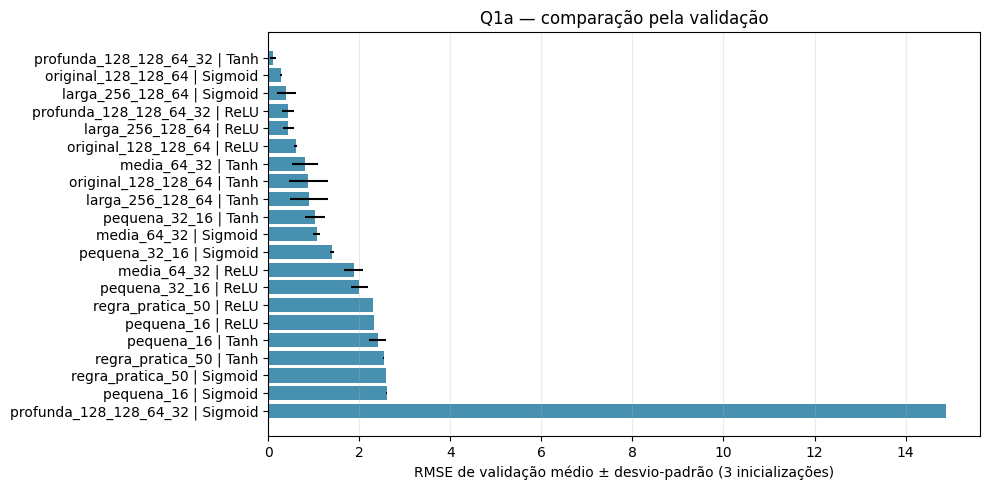

In [3]:
registros_q1a = []
pesos_q1a = {}

for nome, unidades in ARQUITETURAS_Q1A.items():
    for nome_ativacao, ativacao in ATIVACOES_Q1A.items():
        configuracao = f"{nome} | {nome_ativacao}"
        pesos_q1a[configuracao] = []
        for semente in SEMENTES_MODELO:
            keras.backend.clear_session()
            keras.utils.set_random_seed(semente)
            modelo = criar_mlp_q1a(unidades, ativacao)
            parametros = modelo.count_params()
            callbacks = [
                keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=.5,
                                                   patience=12, min_lr=1e-5),
                keras.callbacks.EarlyStopping(monitor="val_loss", patience=40,
                                              restore_best_weights=True),
            ]
            hist = modelo.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                              epochs=500, batch_size=64, callbacks=callbacks,
                              verbose=0)
            prev_va = modelo.predict(X_va, verbose=0).ravel()
            m = metricas_regressao(y_va, prev_va)
            registros_q1a.append({"arquitetura": configuracao,
                                  "ativacao": nome_ativacao,
                                  "semente": semente,
                                  "RMSE_validacao": m["RMSE"],
                                  "MAE_validacao": m["MAE"],
                                  "epocas": len(hist.history["loss"]),
                                  "parametros": parametros})
            pesos_q1a[configuracao].append([w.copy() for w in modelo.get_weights()])
            print(f"{configuracao:42s} semente={semente}: "
                  f"val_RMSE={m['RMSE']:.4f}; épocas={len(hist.history['loss'])}; "
                  f"parâmetros={parametros}")
            del modelo, hist

df_q1a, resumo_q1a = resumo_experimento(registros_q1a)
display(resumo_q1a.round(4))
grafico_resumo(resumo_q1a, "Q1a — comparação pela validação")


### Seleção e avaliação final da Q1a

A menor média de RMSE de validação escolhe a arquitetura candidata. Depois, comparamos essa candidata com a arquitetura anterior no teste reservado. O teste serve para verificar a escolha, não para decidir entre modelos.

Se a diferença entre médias for pequena diante da variação entre inicializações, descrevemos o resultado como inconclusivo. Mesmo quando a diferença é grande, ela vale para este split e esta configuração de treino.


### Procedimento: congelar a escolha e avaliar Q1a

Selecionamos a primeira linha da tabela ordenada pela validação. A rede escolhida e a referência anterior são reconstruídas a partir dos pesos já guardados. Assim, cada métrica de teste corresponde a um modelo efetivamente treinado na busca; nenhum novo ajuste usa o teste.

A tabela agrega MAE, MSE e RMSE das três sementes. Não selecionamos a melhor semente pelo teste, e as previsões não são combinadas em um ensemble. O desvio é calculado entre modelos individuais na mesma amostra de teste. Resultados da referência contextualizam a mudança de arquitetura, mas não isolam uma causa universal para a melhoria.


In [4]:
melhor_q1a = resumo_q1a.iloc[0]["arquitetura"]
original_q1a = "original_128_128_64 | Tanh"
comparar_q1a = list(dict.fromkeys([melhor_q1a, original_q1a]))
resultados_teste_q1a = []

for configuracao in comparar_q1a:
    nome, nome_ativacao = configuracao.split(" | ")
    unidades = ARQUITETURAS_Q1A[nome]
    ativacao = ATIVACOES_Q1A[nome_ativacao]
    for semente, pesos in zip(SEMENTES_MODELO, pesos_q1a[configuracao]):
        pred = predizer_com_pesos(unidades, ativacao, pesos, X_te)
        m = metricas_regressao(y_te, pred)
        resultados_teste_q1a.append({"configuração": configuracao, "semente": semente, **m})

teste_q1a = pd.DataFrame(resultados_teste_q1a)
display(teste_q1a.groupby("configuração")[["MAE", "MSE", "RMSE"]].agg(["mean", "std"]).round(4))
print("Escolhida pela validação:", melhor_q1a)
print("Arquitetura original:", original_q1a)


MAE             MSE            RMSE        
                                 mean     std    mean     std    mean     std
configuração                                                                 
original_128_128_64 | Tanh     0.5797  0.3004  1.0723  0.8041  0.9528  0.4967
profunda_128_128_64_32 | Tanh  0.0504  0.0213  0.0116  0.0134  0.0954  0.0616

Escolhida pela validação: profunda_128_128_64_32 | Tanh
Arquitetura original: original_128_128_64 | Tanh


### Resultado e decisão da Q1a

A validação selecionou **128–128–64–32 com Tanh**, com RMSE médio de validação **0,1012 ± 0,0716**. A arquitetura original 128–128–64 com Tanh obteve **0,8822 ± 0,4251**.

No teste, a arquitetura selecionada teve **RMSE 0,0954 ± 0,0616** e **MAE 0,0504 ± 0,0213**. A original teve **RMSE 0,9528 ± 0,4967** e **MAE 0,5797 ± 0,3004**. Nesse experimento, a arquitetura selecionada reduziu bastante o erro de teste. Ela tem 27.137 parâmetros — cerca de 8% a mais que a original —, pois adicionamos a camada de 32 neurônios.

Tanh foi a melhor ativação para a arquitetura vencedora nesta comparação. Isso não quer dizer que seja sempre melhor: por exemplo, na arquitetura original, Sigmoid teve RMSE de validação menor do que Tanh. O resultado depende da combinação entre arquitetura, ativação e treinamento.

**Limitação:** duas das três execuções da arquitetura selecionada chegaram ao limite de 500 épocas. A comparação demonstra um resultado promissor, mas o limite de treino pode ter influenciado as métricas. As três inicializações também não medem a variação causada por outros splits.


### Curvas e ajuste da Q1a

A curva de perda mostra como o erro de treino e o de validação evoluem por época. Se ambos caem, a rede ainda aprende; se o erro de treino cai enquanto o de validação sobe, há sinal de sobreajuste. O segundo gráfico compara a função conhecida com a previsão da rede no teste, ordenada pelo valor de x.


### Procedimento: uma execução representativa e seus gráficos

Retreinamos a arquitetura escolhida com a primeira semente da lista para obter um histórico completo. Esse é um treino adicional de documentação, além dos 63 da busca. A métrica impressa nesta célula pertence a uma inicialização, enquanto a tabela anterior resume três; os valores não precisam coincidir exatamente.

À esquerda, a perda MSE é acompanhada no treino e na validação. À direita, os pontos mostram os valores reais de teste, e a linha laranja mostra as previsões ordenadas por x. Ordenar x serve apenas para desenhar uma curva sem ligações fora de ordem; não altera o treinamento nem a avaliação. A comparação permite examinar desvios nas oscilações e nas extremidades do intervalo, além da proximidade visual global.


Arquitetura: [128, 128, 64, 32] | ativação: Tanh
Épocas: 418
Métricas de teste nesta inicialização: {'MAE': 0.052093323320150375, 'MSE': 0.0058370972983539104, 'RMSE': 0.07640089854415268}


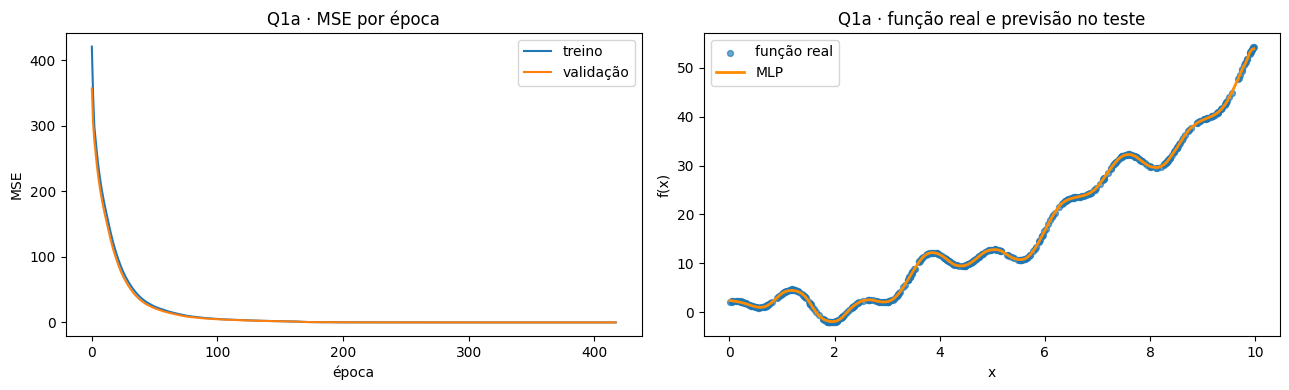

In [5]:
# Treina a arquitetura selecionada com uma das sementes usadas na busca
nome_arq_q1a, nome_ativ_q1a = melhor_q1a.split(" | ")
unidades_final_q1a = ARQUITETURAS_Q1A[nome_arq_q1a]
ativacao_final_q1a = ATIVACOES_Q1A[nome_ativ_q1a]

keras.backend.clear_session()
keras.utils.set_random_seed(SEMENTES_MODELO[0])
modelo_final_q1a = criar_mlp_q1a(unidades_final_q1a, ativacao_final_q1a)
callbacks_final_q1a = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=12, min_lr=1e-5
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=40, restore_best_weights=True
    ),
]
hist_final_q1a = modelo_final_q1a.fit(
    X_tr, y_tr, validation_data=(X_va, y_va),
    epochs=500, batch_size=64, callbacks=callbacks_final_q1a, verbose=0
)
pred_final_q1a = modelo_final_q1a.predict(X_te, verbose=0).ravel()
print("Arquitetura:", unidades_final_q1a, "| ativação:", nome_ativ_q1a)
print("Épocas:", len(hist_final_q1a.history["loss"]))
print("Métricas de teste nesta inicialização:", metricas_regressao(y_te, pred_final_q1a))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist_final_q1a.history["loss"], label="treino")
ax[0].plot(hist_final_q1a.history["val_loss"], label="validação")
ax[0].set(title="Q1a · MSE por época", xlabel="época", ylabel="MSE")
ax[0].legend()

ordem_q1a = np.argsort(x_te)
ax[1].scatter(x_te, y_te, s=18, alpha=0.65, label="função real")
ax[1].plot(x_te[ordem_q1a], pred_final_q1a[ordem_q1a],
           color="darkorange", linewidth=2, label="MLP")
ax[1].set(title="Q1a · função real e previsão no teste", xlabel="x", ylabel="f(x)")
ax[1].legend()
plt.tight_layout()
plt.show()


## 3. Q1b — prever a progressão do diabetes

Usamos o conjunto Diabetes do Scikit-Learn: **442 pessoas e 10 atributos de entrada**. Os atributos incluem idade, sexo, índice de massa corporal, pressão arterial e seis medidas sanguíneas. O alvo é uma medida quantitativa da progressão da doença um ano depois da medição inicial; não é diagnóstico e não indica causalidade.

A divisão é 282 exemplos para treino, 71 para validação e 89 para teste. O escalonador é ajustado somente no treino e aplicado da mesma forma à validação e ao teste. Como são poucos exemplos, aumentar muito a capacidade pode aumentar o sobreajuste; por isso comparamos redes pequenas, médias, grandes e uma rede com 2 neurônios.


### Procedimento: carregar e separar Q1b

`load_diabetes` fornece 442 observações com dez atributos e um alvo contínuo de progressão após um ano. As variáveis são idade, sexo, BMI, pressão e seis medidas séricas. A codificação numérica de sexo não deve ser interpretada como grandeza contínua física. A previsão é associativa, sem demonstrar causalidade ou utilidade clínica.

A mesma regra 64%/16%/20% produz 282/71/89 exemplos por causa do arredondamento. A divisão é aleatória, sem estratificação por faixas do alvo. Os preditores fornecidos pelo Scikit-Learn já vêm escalonados por padrão; o StandardScaler adicional ajustado no treino mantém o protocolo usado na comparação. O alvo permanece na unidade original.


In [6]:
diabetes = load_diabetes(as_frame=True)
Xd = diabetes.data.to_numpy(dtype="float32")
yd = diabetes.target.to_numpy(dtype="float32")
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(
    Xd, yd, test_size=.20, random_state=SEMENTE_DADOS)
Xd_tr, Xd_va, yd_tr, yd_va = train_test_split(
    Xd_tr, yd_tr, test_size=.20, random_state=SEMENTE_DADOS)

scaler_d = StandardScaler().fit(Xd_tr)
Xd_tr = scaler_d.transform(Xd_tr).astype("float32")
Xd_va = scaler_d.transform(Xd_va).astype("float32")
Xd_te = scaler_d.transform(Xd_te).astype("float32")
print(f"Treino: {len(yd_tr)} | validação: {len(yd_va)} | teste reservado: {len(yd_te)}")


Treino: 282 | validação: 71 | teste reservado: 89


### Inspeção inicial dos dados da Q1b

O histograma mostra a distribuição do alvo: onde se concentram os valores de progressão e se há caudas ou assimetria. O mapa de correlação mostra quais preditores variam juntos. Correlação é associação entre atributos; não demonstra causalidade nem exige remover automaticamente uma coluna.


### Procedimento: o que a análise exploratória mostra e muda

O histograma revela a escala e a distribuição da variável que tentamos prever. Isso evita interpretar MSE como se estivesse na unidade original e ajuda a reconhecer regiões do alvo com poucos exemplos. O mapa usa correlação de Pearson entre **preditores**: valores próximos de 1 ou −1 indicam associação linear forte, não importância direta para prever o alvo.

Nesta célula a exploração usa a base completa, inclusive valores pertencentes à futura avaliação. Ela não ajusta o scaler nem seleciona formalmente modelos, mas isso limita a alegação de teste totalmente não explorado. Uma extensão mais rigorosa faria essa inspeção somente no treino/desenvolvimento. Não atribuímos a esta figura uma ablação de atributos: este notebook não contém tal comparação. A decisão implementada foi manter as dez entradas e comparar as arquiteturas.


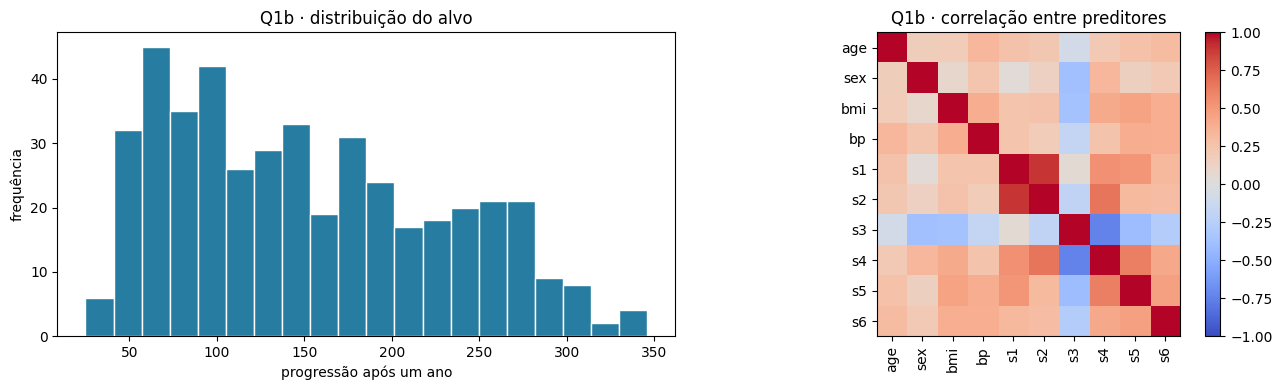

In [7]:
# A distribuição e as correlações são calculadas para inspeção, sem usar o teste para ajustar o modelo
dados_diabetes_df = diabetes.data
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(yd, bins=20, color="#277da1", edgecolor="white")
ax[0].set(title="Q1b · distribuição do alvo", xlabel="progressão após um ano", ylabel="frequência")

corr_diabetes = dados_diabetes_df.corr()
imagem = ax[1].imshow(corr_diabetes, cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(corr_diabetes.columns)), corr_diabetes.columns, rotation=90)
ax[1].set_yticks(range(len(corr_diabetes.columns)), corr_diabetes.columns)
ax[1].set_title("Q1b · correlação entre preditores")
fig.colorbar(imagem, ax=ax[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### Arquiteturas candidatas da Q1b

Todas usam ReLU nas camadas escondidas, uma saída linear, Adam, MSE, lote 32 e parada antecipada. Comparamos tamanhos de 2 até 128 neurônios na primeira camada, incluindo a arquitetura anterior 32–16 e uma rede profunda.

A rede de **2 neurônios** foi incluída para comparar a “regra de ouro” discutida no projeto nas mesmas condições. O número de neurônios é apenas uma parte da capacidade: também contam o número de entradas, camadas, conexões e o modo de treinamento.

A busca escolhe pela menor média do RMSE de validação em três inicializações. Isso oferece evidência para este conjunto de candidatos, mas não prova que um tamanho seja sempre superior.


### Procedimento: capacidade e hipóteses Q1b

Definimos sete redes, incluindo uma camada com apenas dois neurônios e alternativas com duas ou três camadas. Todas usam ReLU, saída linear, Adam 0,001 e MSE. Não há dropout ou penalidade L2 nesta comparação; o controle explícito do tempo de ajuste é o early stopping.

Uma rede pequena é uma hipótese útil porque a amostra é reduzida, mas seu desempenho depende também de otimização, inicialização e orçamento de épocas. Um erro alto na candidata de dois neurônios mostra insuficiência da **configuração treinada neste protocolo**, sem provar que qualquer rede desse tamanho será incapaz em todo treinamento. A escolha exata de 128–64 será apoiada pela validação, não pelo tamanho da base isoladamente.


In [ ]:
ARQUITETURAS_Q1B = {
    "2_neuronios_1_camada": [2],
    "pequena_8": [8],
    "pequena_16_8": [16, 8],
    "original_32_16": [32, 16],
    "media_64_32": [64, 32],
    "larga_128_64": [128, 64],
    "profunda_64_64_32": [64, 64, 32],
}

def criar_mlp_q1b(unidades):
    modelo = keras.Sequential([keras.Input(shape=(Xd_tr.shape[1],))] +
        [layers.Dense(n, activation="relu") for n in unidades] +
        [layers.Dense(1)], name="comparacao_q1b")
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return modelo


### Treinar e comparar na validação

Usamos três inicializações por tamanho. A tabela mostra média e desvio-padrão do RMSE de validação. O desvio ajuda a perceber se a diferença entre duas arquiteturas é pequena diante da variação entre treinos.


### Procedimento: comparar Q1b em condições fixas

São sete arquiteturas × três sementes: **21 treinos de busca**. Usamos lotes de 32, limite de 300 épocas e parada após 30 épocas sem melhora na validação, restaurando os melhores pesos. Os dados, a ativação e a receita permanecem fixos para comparar a distribuição de neurônios.

A tabela registra tanto erro como custo aproximado: parâmetros e épocas. A ordenação usa a média de RMSE de validação, sem uma margem formal de empate. Portanto, diferenças de centésimos podem determinar a primeira linha mesmo quando são muito menores que a variação entre sementes. Essa limitação será considerada na interpretação da rede vencedora.


2_neuronios_1_camada     semente=42: val_RMSE=119.78; épocas=300; parâmetros=25


2_neuronios_1_camada     semente=123: val_RMSE=135.65; épocas=300; parâmetros=25


2_neuronios_1_camada     semente=2026: val_RMSE=121.63; épocas=300; parâmetros=25
pequena_8                semente=42: val_RMSE=80.61; épocas=300; parâmetros=97
pequena_8                semente=123: val_RMSE=94.80; épocas=300; parâmetros=97
pequena_8                semente=2026: val_RMSE=83.54; épocas=300; parâmetros=97
pequena_16_8             semente=42: val_RMSE=56.72; épocas=300; parâmetros=321
pequena_16_8             semente=123: val_RMSE=55.47; épocas=300; parâmetros=321
pequena_16_8             semente=2026: val_RMSE=55.31; épocas=300; parâmetros=321
original_32_16           semente=42: val_RMSE=54.76; épocas=300; parâmetros=897
original_32_16           semente=123: val_RMSE=54.91; épocas=269; parâmetros=897
original_32_16           semente=2026: val_RMSE=54.45; épocas=300; parâmetros=897
media_64_32              semente=42: val_RMSE=54.52; épocas=239; parâmetros=2817
media_64_32              semente=123: val_RMSE=53.74; épocas=295; parâmetros=2817
media_64_32              seme

,arquitetura,RMSE_validacao_medio,RMSE_validacao_dp,MAE_validacao_medio,epocas_media,parametros
0,larga_128_64,54.253,0.473,44.636,181.667,9729
1,media_64_32,54.264,0.454,45.150,278.000,2817
2,original_32_16,54.706,0.234,45.478,289.667,897
3,profunda_64_64_32,55.076,0.431,45.638,137.000,6977
4,pequena_16_8,55.833,0.774,45.850,300.000,321
5,pequena_8,86.319,7.492,72.601,300.000,97
6,2_neuronios_1_camada,125.688,8.681,110.202,300.000,25


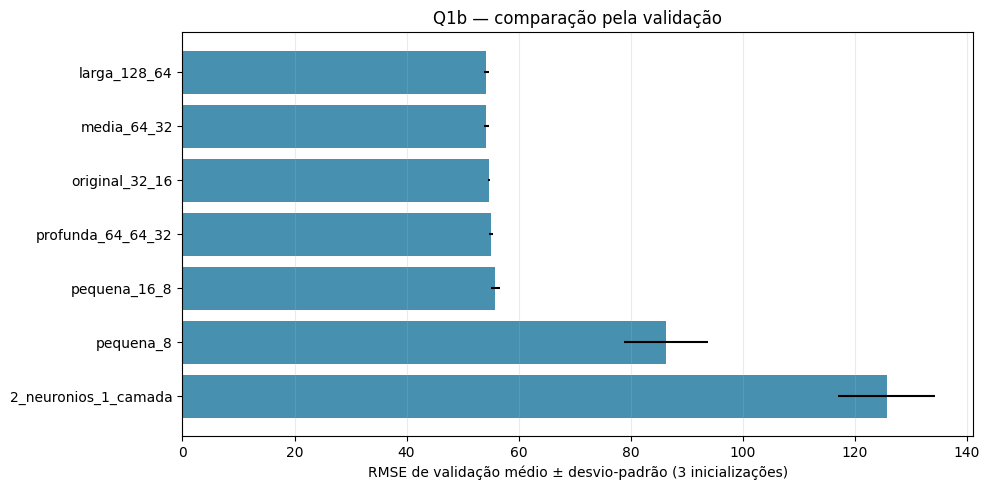

In [8]:
registros_q1b = []
pesos_q1b = {}

for nome, unidades in ARQUITETURAS_Q1B.items():
    pesos_q1b[nome] = []
    for semente in SEMENTES_MODELO:
        keras.backend.clear_session()
        keras.utils.set_random_seed(semente)
        modelo = criar_mlp_q1b(unidades)
        parametros = modelo.count_params()
        callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=30,
                                                 restore_best_weights=True)
        hist = modelo.fit(Xd_tr, yd_tr, validation_data=(Xd_va, yd_va),
                          epochs=300, batch_size=32, callbacks=[callback],
                          verbose=0)
        prev_va = modelo.predict(Xd_va, verbose=0).ravel()
        m = metricas_regressao(yd_va, prev_va)
        registros_q1b.append({"arquitetura": nome, "semente": semente,
                              "RMSE_validacao": m["RMSE"],
                              "MAE_validacao": m["MAE"],
                              "epocas": len(hist.history["loss"]),
                              "parametros": parametros})
        pesos_q1b[nome].append([w.copy() for w in modelo.get_weights()])
        print(f"{nome:24s} semente={semente}: val_RMSE={m['RMSE']:.2f}; "
              f"épocas={len(hist.history['loss'])}; parâmetros={parametros}")
        del modelo, hist

df_q1b, resumo_q1b = resumo_experimento(registros_q1b)
display(resumo_q1b.round(3))
grafico_resumo(resumo_q1b, "Q1b — comparação pela validação")


### Seleção e avaliação final da Q1b

A validação escolhe a rede com menor RMSE médio. Depois, avaliamos no teste reservado essa candidata e a arquitetura anterior 32–16. A regressão linear serve como referência simples, para saber se a MLP melhora o resultado. O teste não participa da escolha nem do ajuste dos pesos.


### Procedimento: teste final e referência linear Q1b

A rede selecionada e a referência 32–16 são avaliadas nas três inicializações usando os pesos guardados. A regressão linear é ajustada nos mesmos exemplos de treino escalonados e avaliada nos mesmos 89 exemplos de teste. Ela fornece uma referência simples: ganhos pequenos da rede precisam ser ponderados contra a complexidade adicional.

A regressão linear recebe apenas um ajuste, enquanto as redes têm média e desvio de três treinos. Não existe uma busca de hiperparâmetros da referência linear nesta célula. MAE, MSE e RMSE são reportados juntos para mostrar o tamanho típico dos desvios e a influência dos erros maiores.


In [9]:
melhor_q1b = resumo_q1b.iloc[0]["arquitetura"]
original_q1b = "original_32_16"
comparar_q1b = list(dict.fromkeys([melhor_q1b, original_q1b]))
resultados_teste_q1b = []

for nome in comparar_q1b:
    unidades = ARQUITETURAS_Q1B[nome]
    for semente, pesos in zip(SEMENTES_MODELO, pesos_q1b[nome]):
        pred = predizer_com_pesos(unidades, "relu", pesos, Xd_te)
        m = metricas_regressao(yd_te, pred)
        resultados_teste_q1b.append({"arquitetura": nome, "semente": semente, **m})

modelo_linear = LinearRegression().fit(Xd_tr, yd_tr)
pred_linear_te = modelo_linear.predict(Xd_te)
m_linear = metricas_regressao(yd_te, pred_linear_te)

teste_q1b = pd.DataFrame(resultados_teste_q1b)
resumo_teste_q1b = (teste_q1b.groupby("arquitetura")[["MAE", "MSE", "RMSE"]]
                    .agg(["mean", "std"]).round(2))
display(resumo_teste_q1b)
display(pd.DataFrame([{"modelo": "Regressão linear", **m_linear}]).round(2))
print("Escolhida pela validação:", melhor_q1b, ARQUITETURAS_Q1B[melhor_q1b])
print("Arquitetura original:", original_q1b, ARQUITETURAS_Q1B[original_q1b])


MAE            MSE          RMSE      
                 mean   std     mean    std   mean   std
arquitetura                                             
larga_128_64    41.93  0.22  2737.13  20.96  52.32  0.20
original_32_16  42.84  0.59  2826.30  54.99  53.16  0.52

,modelo,MAE,MSE,RMSE
0,Regressão linear,42.91,2910.86,53.95


Escolhida pela validação: larga_128_64 [128, 64]
Arquitetura original: original_32_16 [32, 16]


### Resultado e decisão da Q1b

A rede **128–64 com ReLU** teve o menor RMSE médio de validação: **54,253 ± 0,473**. No teste, obteve **RMSE 52,32 ± 0,20** e **MAE 41,93 ± 0,22**. A rede anterior 32–16 obteve **RMSE 53,16 ± 0,52** e a regressão linear, **53,95**.

O ganho de 128–64 sobre 32–16 no teste é modesto. Além disso, a rede 64–32 teve RMSE médio de validação **54,264 ± 0,454**, praticamente igual ao de 128–64. Portanto, seguimos a regra definida e selecionamos 128–64 pela menor média, mas não há evidência forte de que ela seja claramente superior a 64–32. A arquitetura escolhida tem 9.729 parâmetros, contra 897 da 32–16; a melhoria observada deve ser ponderada contra essa complexidade adicional.

A candidata de **2 neurônios** teve RMSE médio de validação **125,688 ± 8,681**, muito pior que as redes maiores. Neste conjunto, nesta divisão e com este treinamento, essa rede pequena não representou capacidade suficiente para aprender a relação com erro comparável às demais. Isso não invalida uma regra prática como intuição geral; mostra que ela não é uma garantia de bom desempenho aqui.

A regressão linear é um ponto de referência, não uma concorrente obrigatória. O ganho da MLP sobre ela também é pequeno, então não afirmamos superioridade universal.


### Curva de treino e previsões da Q1b

A primeira figura acompanha MSE de treino e validação; a segunda compara cada alvo real com a previsão da MLP no teste. Quanto mais perto os pontos ficam da diagonal, mais próximas são as previsões. A linha não é uma meta independente: é a referência de previsão perfeita.


### Procedimento: curvas e dispersão da Q1b

Repetimos o treinamento selecionado com semente 42 para registrar o histórico e exibir previsões. Trata-se de uma execução representativa, não da melhor escolhida no teste. A curva de MSE permite observar se o treino continua melhorando enquanto a validação deixa de acompanhar.

No gráfico real versus previsto, cada ponto é uma observação do teste. A reta diagonal representa previsão perfeita; a distância vertical até ela é o erro daquele exemplo. Concentração das previsões perto da média pode coexistir com métricas moderadas e perda de extremos. O gráfico ajuda a identificar esse padrão, mas não prova que um atributo específico o causou.


Arquitetura selecionada: [128, 64]
Épocas: 212
Métricas de teste nesta inicialização: {'MAE': 41.83934020996094, 'MSE': 2726.7353515625, 'RMSE': 52.2181515525253}


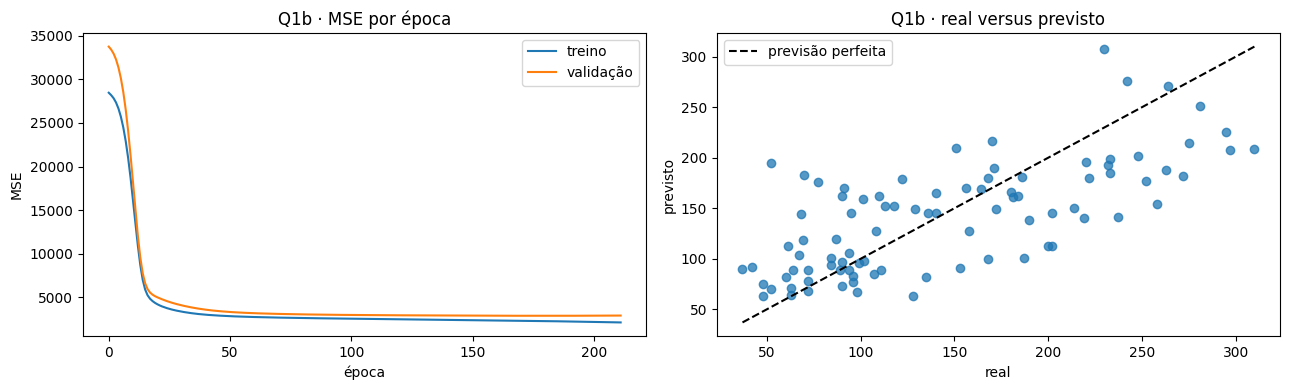

In [10]:
# Treina a arquitetura selecionada com uma das sementes usadas na busca
keras.backend.clear_session()
keras.utils.set_random_seed(SEMENTES_MODELO[0])
modelo_final_q1b = criar_mlp_q1b(ARQUITETURAS_Q1B[melhor_q1b])
callback_final_q1b = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=30, restore_best_weights=True
)
hist_final_q1b = modelo_final_q1b.fit(
    Xd_tr, yd_tr, validation_data=(Xd_va, yd_va),
    epochs=300, batch_size=32, callbacks=[callback_final_q1b], verbose=0
)
pred_final_q1b = modelo_final_q1b.predict(Xd_te, verbose=0).ravel()
print("Arquitetura selecionada:", ARQUITETURAS_Q1B[melhor_q1b])
print("Épocas:", len(hist_final_q1b.history["loss"]))
print("Métricas de teste nesta inicialização:", metricas_regressao(yd_te, pred_final_q1b))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist_final_q1b.history["loss"], label="treino")
ax[0].plot(hist_final_q1b.history["val_loss"], label="validação")
ax[0].set(title="Q1b · MSE por época", xlabel="época", ylabel="MSE")
ax[0].legend()

ax[1].scatter(yd_te, pred_final_q1b, alpha=0.75)
limites = [
    min(float(yd_te.min()), float(pred_final_q1b.min())),
    max(float(yd_te.max()), float(pred_final_q1b.max())),
]
ax[1].plot(limites, limites, "k--", label="previsão perfeita")
ax[1].set(title="Q1b · real versus previsto", xlabel="real", ylabel="previsto")
ax[1].legend()
plt.tight_layout()
plt.show()


## 4. Conclusões

### Q1a

A função combina oscilações e crescimento quadrático. Mantivemos os exemplos e a divisão fixos e comparamos tamanhos de rede e três ativações, usando RMSE médio de validação em três inicializações. A combinação 128–128–64–32 com Tanh foi a melhor entre as testadas e também teve erro menor no teste do que a rede original. Como duas execuções chegaram ao limite de 500 épocas e usamos só um split, apresentamos isso como a melhor opção observada neste experimento, não como a rede ótima em geral.
### Q1b

A base tem 442 exemplos e 10 atributos, então avaliamos arquiteturas de vários tamanhos e comparamos também com regressão linear. A rede de 2 neurônios teve erro de validação muito alto. A rede 128–64 foi a selecionada pela menor média de validação e teve uma melhora modesta no teste em relação à rede anterior. Como 64–32 ficou praticamente empatada na validação, não afirmamos que exatamente 128 e 64 neurônios sejam universalmente necessários.
### Limites importantes

- Os três treinos de cada arquitetura mudam a inicialização, mas usam o mesmo split. Eles não medem variação entre amostras ou entre divisões de dados.
- A comparação cobre apenas as arquiteturas e hiperparâmetros listados.
- Q1a tem exemplos sintéticos sem ruído; seu resultado não representa automaticamente dados reais.
- Q1b é uma base pequena. A previsão é associativa e não deve ser interpretada como diagnóstico ou explicação causal.
- Resultados com mais casas decimais não tornam uma diferença pequena mais confiável. A interpretação das diferenças considera a dispersão entre inicializações.


## Síntese numérica e alcance da resposta

| Parte e modelo escolhido | MAE no teste | MSE no teste | RMSE no teste |
|---|---:|---:|---:|
| Q1a: 128–128–64–32 Tanh | 0,0504 ± 0,0213 | 0,0116 ± 0,0134 | 0,0954 ± 0,0616 |
| Q1b: 128–64 ReLU | 41,93 ± 0,22 | 2.737,13 ± 20,96 | 52,32 ± 0,20 |

São médias e desvios entre três inicializações no mesmo teste, calculados separadamente para cada métrica. A raiz do MSE médio não precisa ser exatamente igual ao RMSE médio. Q1a e Q1b têm escalas distintas: comparar seus MSE diretamente não mede qual tarefa foi melhor resolvida.

Na Q1b, 128–64 e 64–32 ficaram praticamente empatadas na validação (54,253 contra 54,264). O ganho pequeno sobre regressão linear (RMSE 53,95) recomenda uma conclusão moderada sobre complexidade. Na Q1a, a aproximação foi precisa no intervalo amostrado, sem testar extrapolação. Os requisitos de curvas, comparação real/predito e métricas estão presentes nas saídas preservadas.

### Referências

- Scikit-Learn: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html
- Scikit-Learn, padronização: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- Keras, parada antecipada: https://keras.io/api/callbacks/early_stopping/

Os links são referências para consulta; os resultados deste documento vêm das saídas do experimento registrado.
